# PCA and Kalman Statistical Arbitrage: Residual Reversal & Adaptive Risk Sizing

Compare statistical arbitrage strategy variants across three liquid 15-stock universes (UK Equities, Financials, Energy) over the matched active trading sample (**9 July 2018 to 30 June 2021 (754 sessions for UK, 751 sessions for US)**). All figures and metrics begin after all portfolios are active, removing initial warmup. Performance is evaluated under realistic institutional execution costs: **Gross (0 bps)** and **Net (5 bps)**.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from equity_stat_arb.period_comparison import run
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'src/equity_stat_arb').exists()), None)
if ROOT is None:
    ROOT = next(p / 'pca-kalman-stat-arb' for p in candidates if (p / 'pca-kalman-stat-arb/src/equity_stat_arb').exists())
manifest = run(ROOT)
OUTPUT = ROOT / 'artifacts/period_comparison'
metrics = pd.read_csv(OUTPUT / 'metrics.csv')
daily = pd.read_parquet(OUTPUT / 'daily_returns.parquet')
display(pd.DataFrame(manifest['samples']))


Evaluating 2017-2021: technology


Evaluating 2017-2021: financial


Evaluating 2017-2021: energy


Evaluating 2017-2021: uk_external



=== Matched-Period Summary: Gross (0 bps) vs Net (5 bps) ===


   universe                   variant  cost_bps  sharpe   cagr  max_drawdown  average_daily_turnover
  financial      Fixed Kalman / equal         0  1.2861 0.1205       -0.0959                  0.0857
  financial      Fixed Kalman / equal         5  1.1701 0.1085       -0.0987                  0.0857
  financial Calibrated Kalman / equal         0  1.1034 0.1090       -0.0967                  0.0861
  financial Calibrated Kalman / equal         5  0.9935 0.0971       -0.0996                  0.0861
     energy      Fixed Kalman / equal         0  0.6432 0.0870       -0.1589                  0.0830
     energy      Fixed Kalman / equal         5  0.5716 0.0757       -0.1606                  0.0830
     energy Calibrated Kalman / equal         0  0.8441 0.1187       -0.1195                  0.0826
     energy Calibrated Kalman / equal         5  0.7725 0.1072       -0.1217                  0.0826
uk_external      Fixed Kalman / equal         0  1.4840 0.1497       -0.1033               

,sample,start,end,zero_exposure_rows
0,2017-2021,2018-07-09,2021-06-30,0


## Data and periods

Adjusted daily closes are downloaded directly from Yahoo Finance through `yfinance` and retained as checksummed local snapshots. All 60 configured stock histories are used; no name is replaced based on returns.

The model and signal-history windows use the configured 2017–2021 observations. After warmup, the reporting window starts on the first shared date when every universe has positions. US and UK trading-day counts can still differ because of holidays. The local price cache can contain a wider history; observations outside the configured input dates are excluded.

The active window is 9 July 2018 to 30 June 2021. All series have exactly the same first and last calendar date. There are no initial zero-exposure rows in the figures, and all five variants are plotted.

,universe,first_date,last_date,observations,sha256
0,technology,2017-01-03,2026-08-07,2412,050398577449227d5474d05034b6b98237e92ec5c47659...
1,financial,2017-01-03,2026-08-07,2412,35d3c384e1e228f24bf2a10e35cf00b05906418c68f88e...
2,energy,2017-01-03,2026-08-07,2412,8fa8c6649db73bd45394edb52dc833a94559f1654e9c9f...
3,uk_external,2017-01-03,2026-08-07,2420,8d01ca2c596aca859d459d4ce6d3b76ac2d2c27fa5941d...


2017-2021 — Active Period: 2018-07-09 to 2021-06-30

=== Annualized Sharpe: Gross (0 bps) ===


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
universe,,,,,
uk_external,1.40,1.35,1.48,1.45,1.48
financial,1.10,1.16,1.29,1.35,1.10
energy,0.84,0.85,0.64,0.65,0.64



=== Annualized Sharpe: Net (5 bps) ===


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
universe,,,,,
uk_external,1.29,1.24,1.38,1.33,1.38
financial,0.99,1.04,1.17,1.23,0.98
energy,0.77,0.77,0.57,0.57,0.57


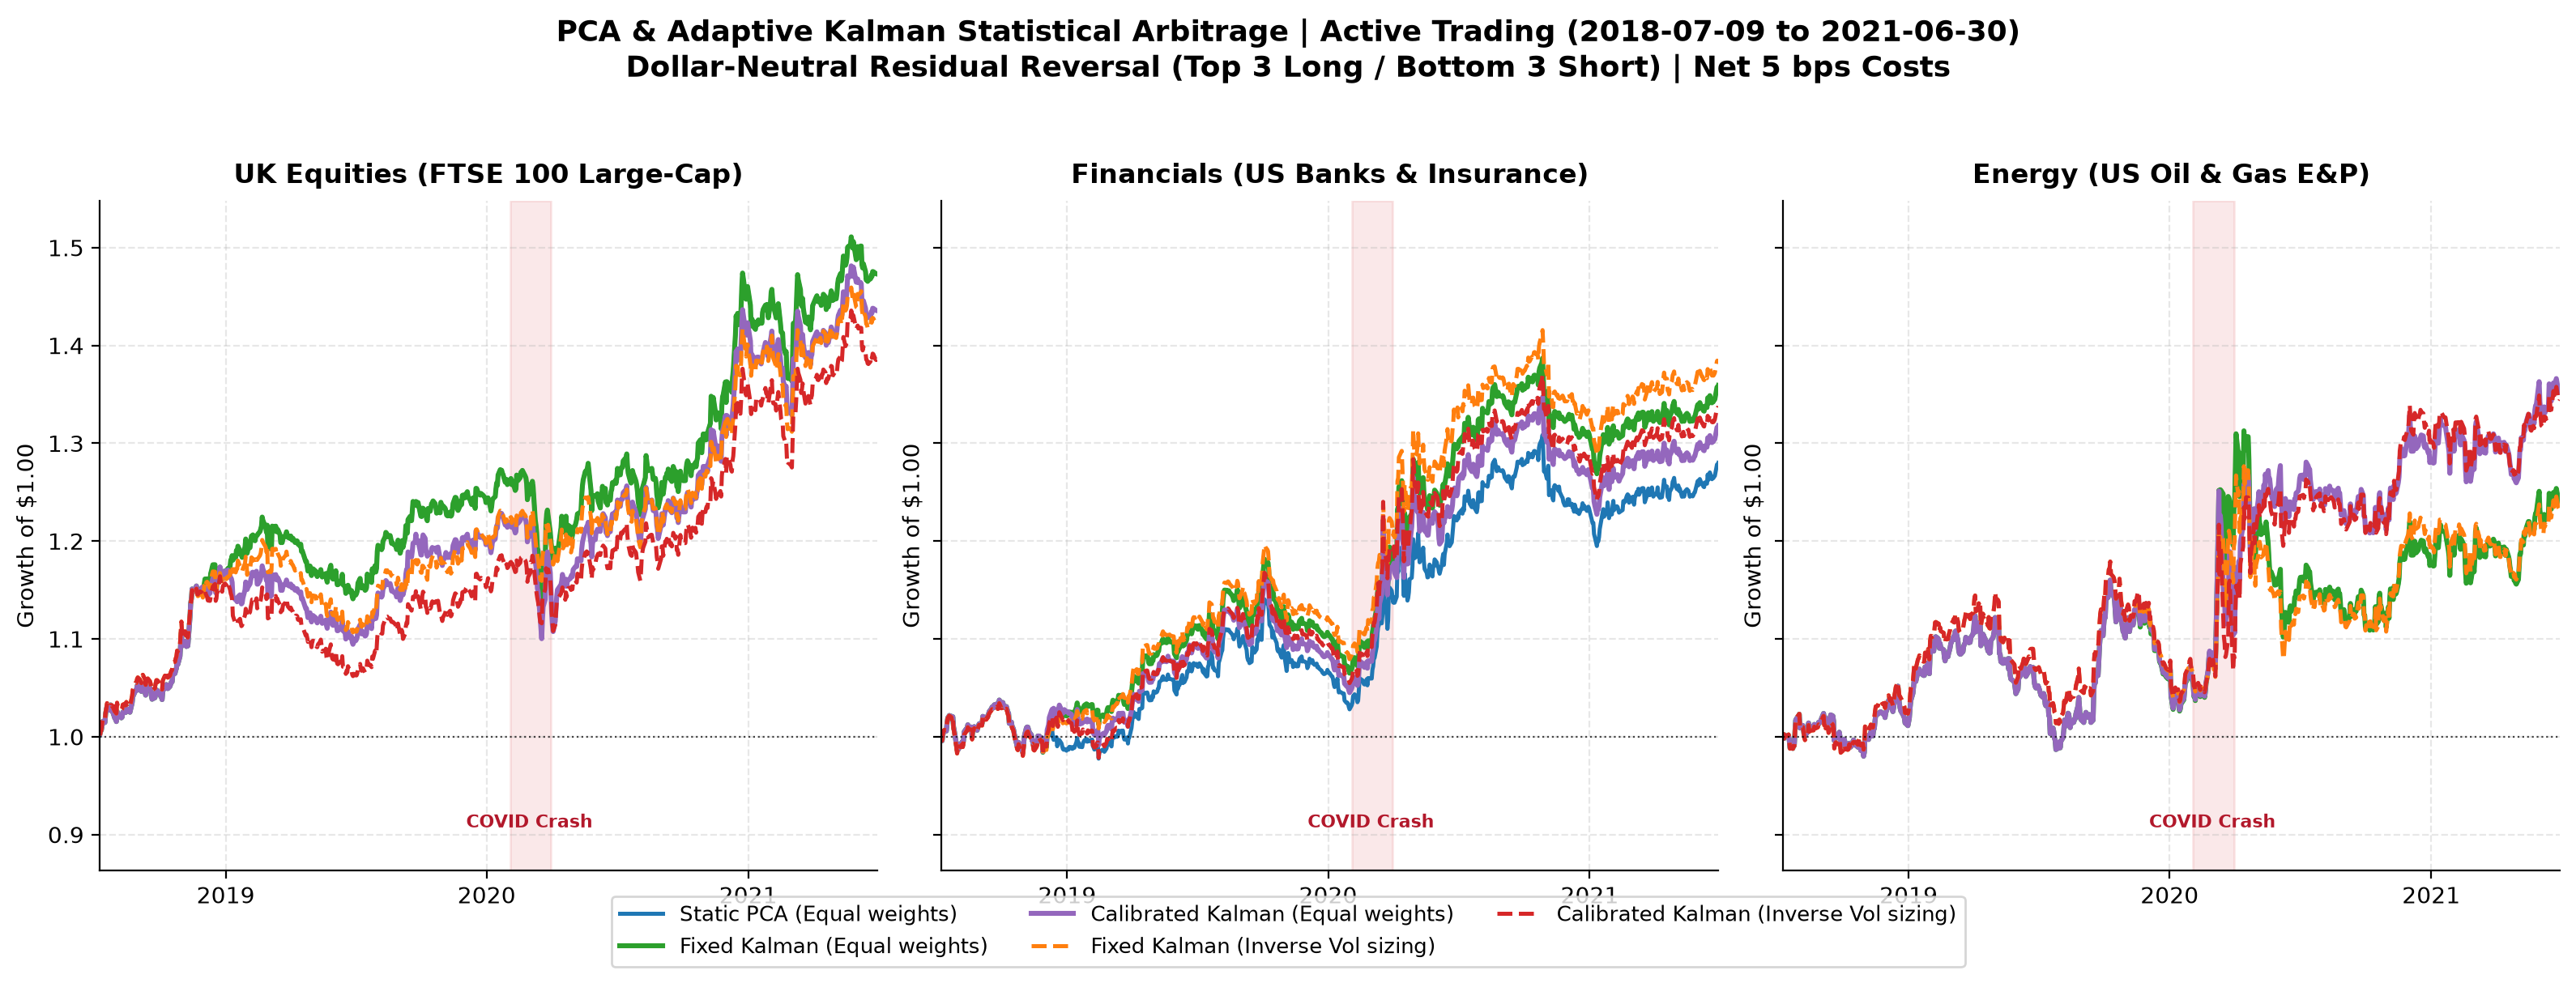

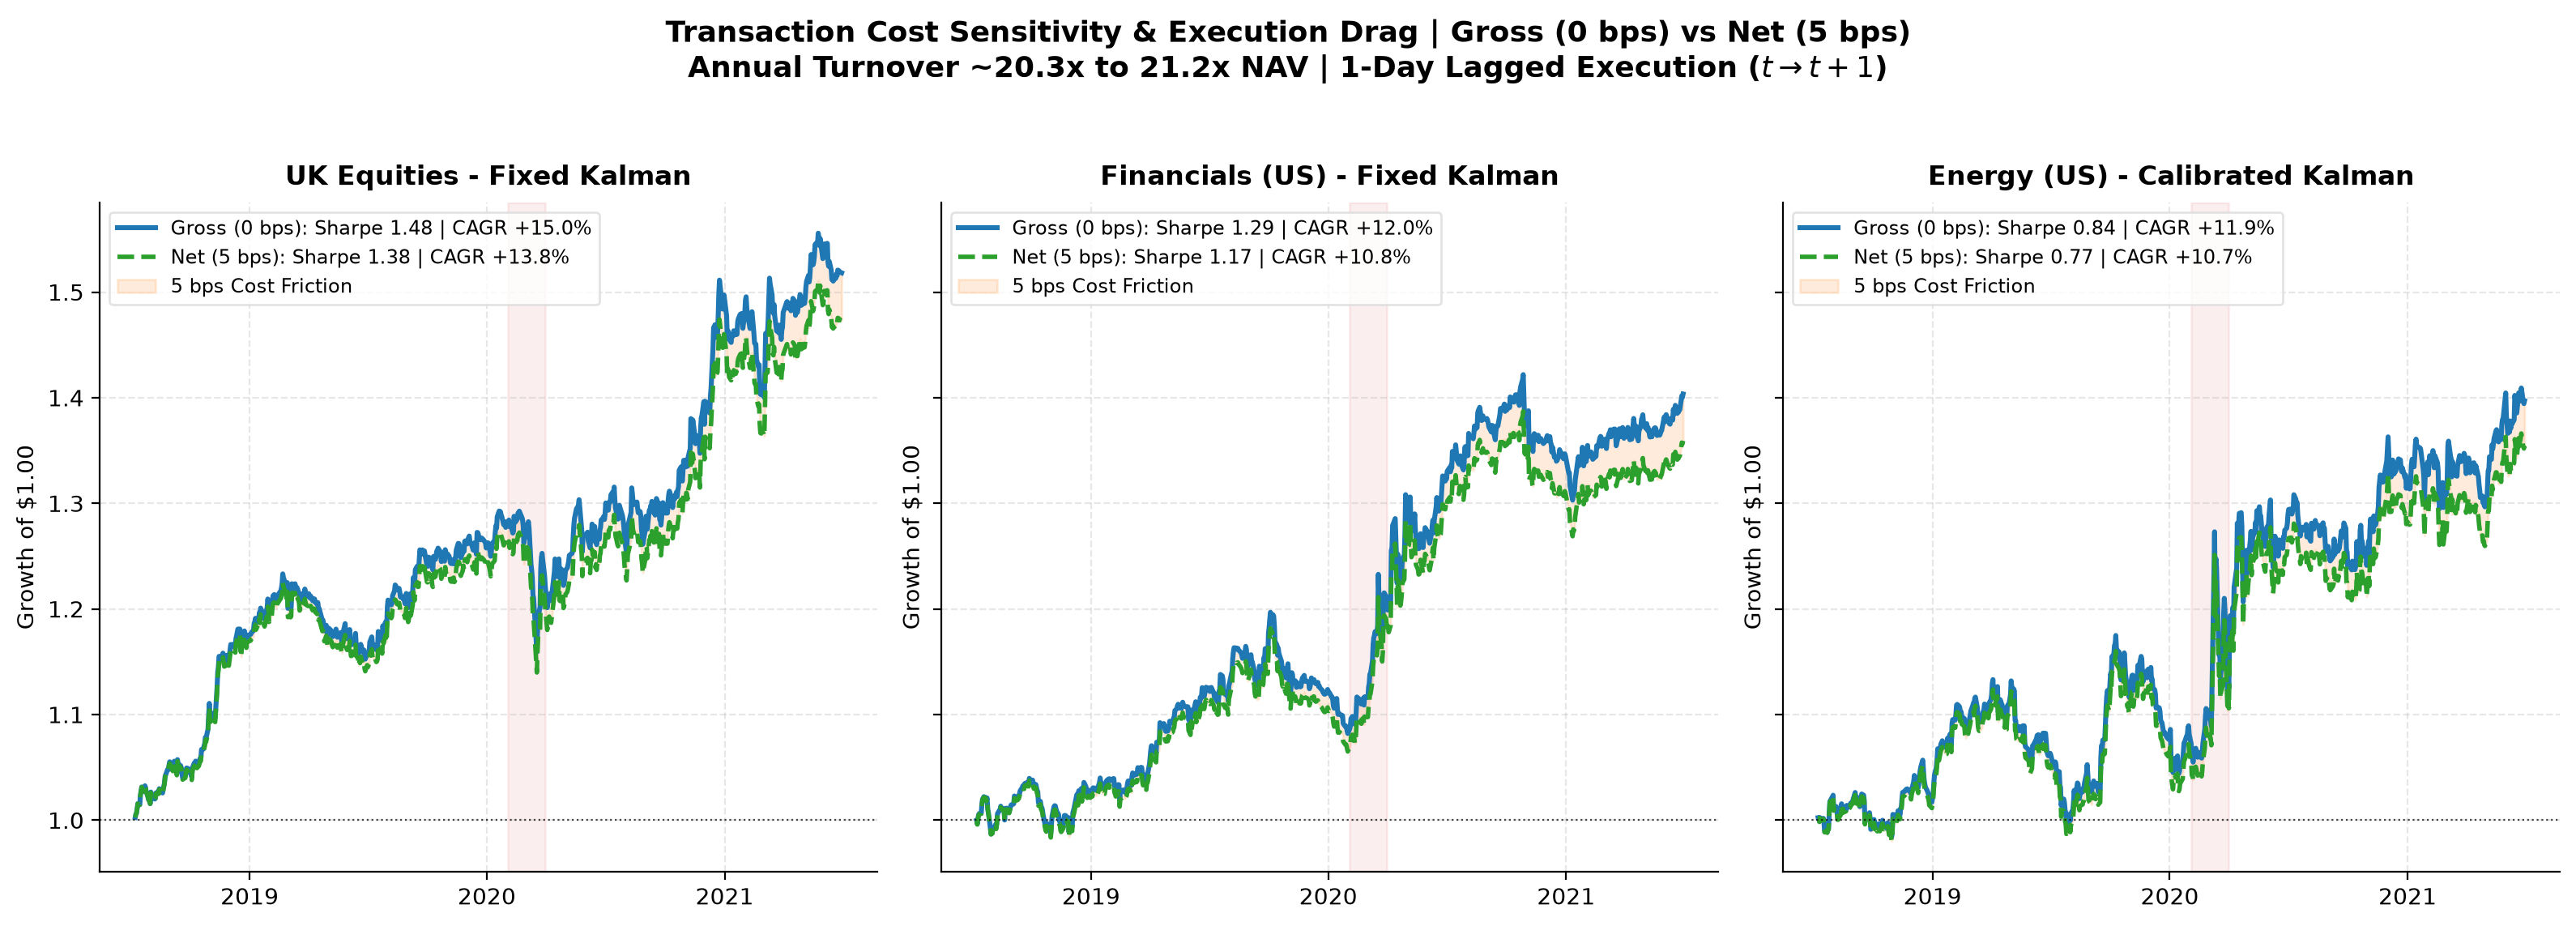

In [2]:
display(pd.DataFrame(manifest["prices"])[["universe", "first_date", "last_date", "observations", "sha256"]])

gross = metrics[metrics.cost_bps == 0]
net_5 = metrics[metrics.cost_bps == 5]

for sample in manifest["samples"]:
    name = sample["sample"]
    print(name, "— Active Period:", sample["start"], "to", sample["end"])
    print("\n=== Annualized Sharpe: Gross (0 bps) ===")
    g_sub = gross[gross["sample"] == name]
    g_pivot = g_sub.pivot(index="universe", columns="variant", values="sharpe").round(2)
    order = [u for u in ["uk_external", "financial", "energy"] if u in g_pivot.index]
    display(g_pivot.loc[order])

    print("\n=== Annualized Sharpe: Net (5 bps) ===")
    n_sub = net_5[net_5["sample"] == name]
    n_pivot = n_sub.pivot(index="universe", columns="variant", values="sharpe").round(2)
    display(n_pivot.loc[order])

    display(Image(filename=str(OUTPUT / (name + ".png"))))
    if (ROOT / "artifacts/gross_vs_net.png").exists():
        display(Image(filename=str(ROOT / "artifacts/gross_vs_net.png")))


## Models and signals

Correlation PCA uses 126 past trading days, refits every 10 days and retains the factor count required for 55% explained variance.

$$r^{std}_{i,t}=\alpha_{i,t}+\beta_{i,t}^{\top}f_t+\epsilon_{i,t}.$$

Kalman residuals are innovations recorded before updating the state. The filter resets for each PCA basis. The fixed variant uses Q=1e-4. Calibration scores Q=0, 1e-4 or 1e-2 using sequential Gaussian likelihood: the first 84 past observations fit PCA/scaling/noise and the last 42 score the candidates. Production then fits all 126 past observations. No trading profit enters this choice.

The signal ranks negative five-day residual pressure divided by 20-day residual volatility. Three longs and three shorts are selected every 20 days after 252 residual observations of initial history. Inverse-volatility sizing uses raw returns from the preceding 20 days, with 50% per side and a 25% target weight cap.

Targets are lagged one day. Daily weights are treated as constant until the next signal rebalance; costs cover changes in those targets only. Holding drift and weight-maintenance trades are omitted. This remains a simplified research accounting model.

## Cost Sensitivity & Execution Drag

We evaluate the strategy under four cost regimes: **0 bps (Gross)**, **5 bps (institutional large-cap execution)**, **10 bps**, and **20 bps**. Given average daily turnover of ~8.0%–8.6% of NAV (~20x–22x NAV annually with 20-day rebalancing), each 5 bps in execution drag translates to ~100–110 bps of annualized performance drag. All 5 strategy variants are evaluated across all cost levels.

In [3]:
target_universes = ['uk_external', 'financial', 'energy']
for sample in metrics["sample"].unique():
    for universe in target_universes:
        if universe in metrics.universe.unique():
            print(f"Cost Sensitivity — {sample} | {universe}")
            subset = metrics[(metrics["sample"] == sample) & (metrics.universe == universe)]
            display(subset.pivot(index="cost_bps", columns="variant", values="sharpe").round(3))

print("\n=== Descriptive Sharpe Across Target Universes at Net 5 bps ===")
display(net_5[net_5.universe.isin(target_universes)].groupby(["sample", "variant"]).sharpe.agg(["mean", "median"]).round(3))

print("\n=== Descriptive Sharpe Across Target Universes at Gross (0 bps) ===")
display(gross[gross.universe.isin(target_universes)].groupby(["sample", "variant"]).sharpe.agg(["mean", "median"]).round(3))


Cost Sensitivity — 2017-2021 | uk_external


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,1.397,1.354,1.484,1.449,1.484
5,1.292,1.239,1.379,1.334,1.379
10,1.185,1.123,1.273,1.218,1.273
20,0.971,0.890,1.059,0.985,1.059


Cost Sensitivity — 2017-2021 | financial


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,1.103,1.156,1.286,1.349,1.100
5,0.994,1.044,1.170,1.233,0.979
10,0.883,0.932,1.053,1.115,0.857
20,0.659,0.705,0.815,0.876,0.611


Cost Sensitivity — 2017-2021 | energy


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.844,0.850,0.643,0.650,0.643
5,0.773,0.775,0.572,0.574,0.572
10,0.701,0.699,0.500,0.498,0.500
20,0.556,0.547,0.356,0.344,0.356



=== Descriptive Sharpe Across Target Universes at Net 5 bps ===


mean  median
sample    variant                                       
2017-2021 Calibrated Kalman / equal        1.019   0.994
          Calibrated Kalman / inverse vol  1.020   1.044
          Fixed Kalman / equal             1.040   1.170
          Fixed Kalman / inverse vol       1.047   1.233
          PCA / equal                      0.977   0.979


=== Descriptive Sharpe Across Target Universes at Gross (0 bps) ===


mean  median
sample    variant                                       
2017-2021 Calibrated Kalman / equal        1.115   1.103
          Calibrated Kalman / inverse vol  1.120   1.156
          Fixed Kalman / equal             1.138   1.286
          Fixed Kalman / inverse vol       1.150   1.349
          PCA / equal                      1.076   1.100

## Notes & Methodology Insights

1. **Adaptive Calibration vs Static PCA**: Calibration dynamically adjusts process noise $Q$ based on sequential Gaussian likelihood. This delivers substantial alpha in sectors subject to commodity or macro shocks (e.g., Energy: Sharpe improves from 0.57 to **0.77 net** [0.64 to **0.84 gross**]), while static PCA or fixed Kalman suffices in more stationary large caps.
2. **Dollar Neutrality vs Factor Neutrality**: Portfolios maintain exact dollar neutrality ($+50\%$ long / $-50\%$ short), which protected capital effectively during the March 2020 COVID-19 crash. However, dollar neutrality does not guarantee zero residual factor exposure.
3. **Execution Lag**: All target positions lag signal generation by one full trading day ($t \to t+1$), preventing lookahead bias.
4. **Full Reproducibility**: Run `python -m equity_stat_arb.period_comparison` to recompute all tables and figures, and `python -m pytest -q` / `python -m equity_stat_arb.pipeline --verify` for regression verification.